# Task 2 — Feature Engineering & Ablation

Every idea is tested with the **same 5 stratified folds** and the **same LightGBM settings**
(400 trees, lr 0.05) so the numbers are directly comparable. Row A (raw features) is the reference.
Feature statistics are fitted on each fold's training part only (`cv_fit_in_fold`), so validation rows never leak into the features.

Feature code lives in `src/features.py` (`FeatureBuilder`), the CV helper in `src/evaluate.py`, and the custom model in `src/models.py`.

1. Ablation: which feature ideas help?
2. The 2×2 picture: composite engagement × spending scores
3. Where the model fails: missing `loyalty_tier`
4. Key discovery: features are independent *within* each segment
5. Additive models: spline logistic regression & histogram Naive Bayes
6. Summary

In [1]:
import sys, warnings
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))
warnings.filterwarnings("ignore")

import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import lightgbm as lgb
from sklearn.metrics import f1_score

from data import load_train, numeric_cols, TARGET, CLASS_NAMES, NOISE_COLS, FIG_DIR, TASK_DIR, SEED
from features import FeatureBuilder
from evaluate import cv_fit_in_fold, get_folds
from models import HistNB

OOF_DIR = TASK_DIR / "artifacts" / "oof"; OOF_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
PALETTE = {"Casual": "#4C72B0", "Grinder": "#DD8452", "Social": "#55A868", "Whale": "#C44E52"}
ORDER = list(CLASS_NAMES.values())

train = load_train()
y = train[TARGET].to_numpy()
folds = get_folds(y)
lgbm = lgb.LGBMClassifier(n_estimators=400, learning_rate=0.05, verbose=-1, random_state=SEED)
results = {}

## 1. Ablation — add one idea at a time

In [2]:
configs = {
    "A raw features":                        dict(drop_noise=False, drop_useless_cats=False, ordinal=False,
                                                  composites=False, ratios=False),
    "B drop noise + 8 useless categoricals": dict(ordinal=False, composites=False, ratios=False),
    "C + ordinal loyalty/engagement":        dict(composites=False, ratios=False),
    "D + composite eng/spend scores":        dict(ratios=False),
    "E + ratio features (full)":             dict(),
    "F composites only (drop raw eng/spend)": dict(keep_raw=False),
}
oofs = {}
for name, cfg in configs.items():
    print(f"{name:42s}", end=" ")
    oofs[name], results[name], _ = cv_fit_in_fold(lgbm, train, y, cfg, folds)
np.save(OOF_DIR / "lgbm_D.npy", oofs["D + composite eng/spend scores"])

A raw features                             

macro F1 0.7491  (folds 0.7491 ± 0.0027)  [44 feats, 38s]
B drop noise + 8 useless categoricals      

macro F1 0.7479  (folds 0.7479 ± 0.0014)  [33 feats, 31s]
C + ordinal loyalty/engagement             

macro F1 0.7482  (folds 0.7482 ± 0.0026)  [33 feats, 26s]
D + composite eng/spend scores             

macro F1 0.7516  (folds 0.7516 ± 0.0017)  [41 feats, 33s]
E + ratio features (full)                  

macro F1 0.7517  (folds 0.7517 ± 0.0023)  [49 feats, 31s]
F composites only (drop raw eng/spend)     

macro F1 0.7444  (folds 0.7444 ± 0.0031)  [31 feats, 23s]


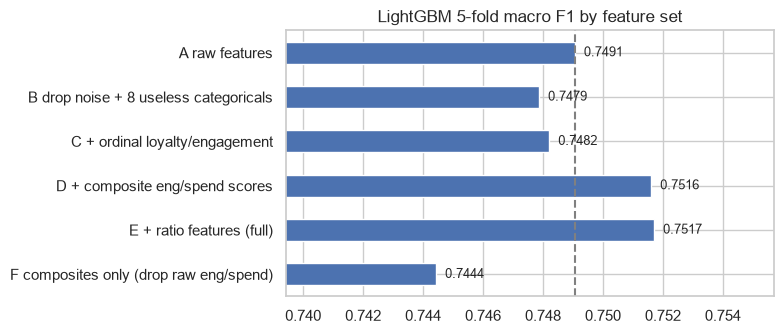

In [3]:
res = pd.Series(results).rename("macro F1")
ax = res.plot.barh(figsize=(8, 3.5), color="#4C72B0"); ax.invert_yaxis()
ax.set_xlim(res.min() - .005, res.max() + .004); ax.axvline(results["A raw features"], ls="--", c="grey")
for i, v in enumerate(res): ax.text(v + .0003, i, f"{v:.4f}", va="center", fontsize=9)
ax.set_title("LightGBM 5-fold macro F1 by feature set"); plt.tight_layout()
plt.savefig(FIG_DIR / "feature_ablation.png", dpi=120); plt.show()

- Dropping the noise and useless columns changes almost nothing (0.7479 vs 0.7491, inside the ±0.002 fold noise), so they really are noise. Simpler is better.
- **Composite scores give the only clear gain (+0.003 over C, to 0.7516)**. Ratio features add nothing (0.7517).
- The composites can't *replace* the raw columns (F drops to 0.7444): the raw columns still carry information the plain average loses.

## 2. The 2×2 picture

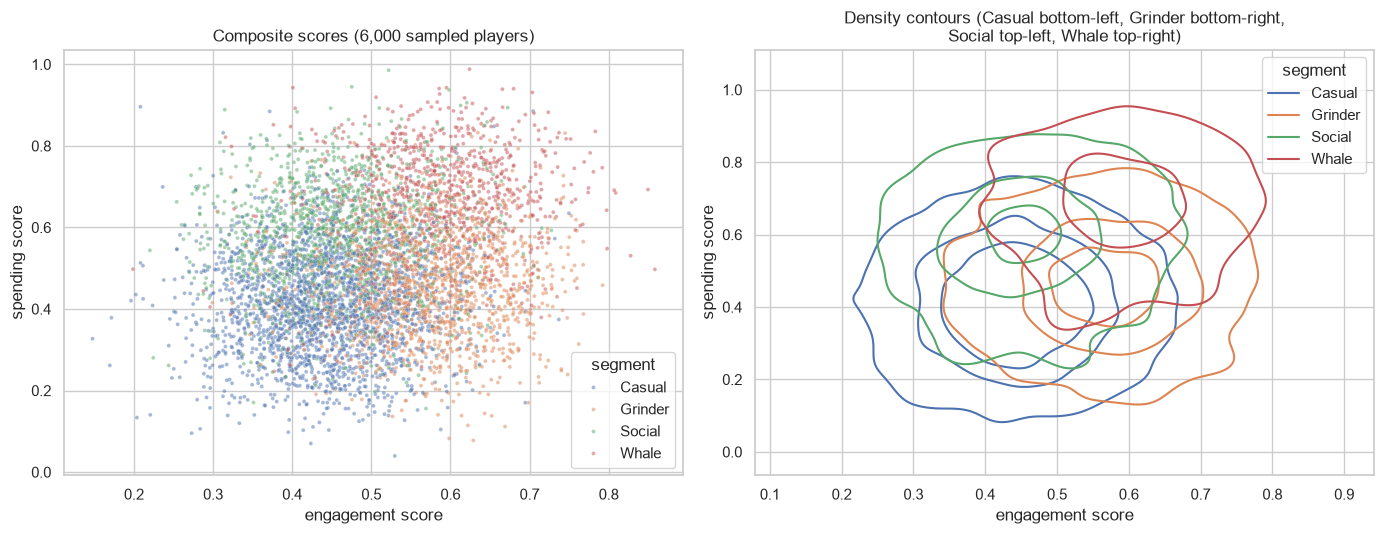

,eng_score,spend_score,loyalty_tier,engagement_level
segment,,,,
Casual,0.442,0.416,0.616,0.611
Grinder,0.572,0.462,0.620,1.480
Social,0.460,0.583,2.436,0.611
Whale,0.585,0.668,2.415,1.478


In [4]:
fb = FeatureBuilder().fit(train); Xf = fb.transform(train)
plot = pd.DataFrame({"engagement score": Xf["eng_score"], "spending score": Xf["spend_score"],
                     "segment": train[TARGET].map(CLASS_NAMES)}).sample(6000, random_state=SEED)
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
sns.scatterplot(data=plot, x="engagement score", y="spending score", hue="segment", hue_order=ORDER,
                palette=PALETTE, s=8, alpha=.5, ax=axes[0])
axes[0].set_title("Composite scores (6,000 sampled players)")
sns.kdeplot(data=plot, x="engagement score", y="spending score", hue="segment", hue_order=ORDER,
            palette=PALETTE, levels=4, ax=axes[1])
axes[1].set_title("Density contours (Casual bottom-left, Grinder bottom-right,\nSocial top-left, Whale top-right)")
plt.tight_layout(); plt.savefig(FIG_DIR / "composite_2x2.png", dpi=120); plt.show()
display(Xf.groupby(train[TARGET].map(CLASS_NAMES))[["eng_score", "spend_score", "loyalty_tier", "engagement_level"]]
        .mean().loc[ORDER].round(3))

The four segments sit in the four corners as expected, but the clouds **overlap heavily**. That overlap is noise built into the data, and it limits how high any model can score.

## 3. Where does the model fail?

In [5]:
pred = oofs["E + ratio features (full)"].argmax(1)
miss = train[["loyalty_tier", "engagement_level"]].isna()
groups = {"both ordinals present": ~miss.any(axis=1), "loyalty_tier missing": miss["loyalty_tier"],
          "engagement_level missing": miss["engagement_level"]}
display(pd.DataFrame({k: {"rows": int(m.sum()), "macro F1": round(f1_score(y[m], pred[m], average="macro"), 4)}
                      for k, m in groups.items()}).T)
acc = (pd.DataFrame({"loyalty": train["loyalty_tier"].fillna("NA"), "engagement": train["engagement_level"].fillna("NA"),
                     "correct": y == pred}).groupby(["loyalty", "engagement"])["correct"].agg(["mean", "size"]))
display(acc.sort_values("mean").head(8).round(3))

,rows,macro F1
both ordinals present,88459.0,0.7626
loyalty_tier missing,8025.0,0.6441
engagement_level missing,8162.0,0.7272


mean   size
loyalty engagement              
NA      Mid         0.637   2924
Gold    Mid         0.647   6056
        NA          0.663   1218
NA      NA          0.667    646
Gold    Low         0.675   5054
NA      High        0.677   1639
Gold    High        0.679   3426
Silver  Mid         0.692  11682

- When `loyalty_tier` is missing, macro F1 drops to **0.64** (vs 0.76). It is the single strongest clue for the spending axis.
- The middle tiers (Gold/Silver × Mid, and rows with `loyalty_tier` missing) are the hardest. Those players sit in the overlap zone.
- `loyalty_tier` is *not* a function of spending (median spend by tier: Bronze 27k, Silver 30k, Gold 36k, Platinum 42k, Diamond 41k). It is a separate noisy signal, so we **can't recover it** from the other columns.

## 4. Key discovery: features are independent *within* each segment

In [6]:
num = [c for c in numeric_cols(train) if c not in NOISE_COLS]
rows = {}
for k, name in CLASS_NAMES.items():
    cm = train.loc[y == k, num].corr().abs().to_numpy()
    tri = cm[np.triu_indices_from(cm, 1)]
    rows[name] = {"max |corr|": tri.max(), "mean |corr|": tri.mean()}
pooled = train[num].corr().abs().to_numpy(); tri = pooled[np.triu_indices_from(pooled, 1)]
rows["ALL (pooled)"] = {"max |corr|": tri.max(), "mean |corr|": tri.mean()}
display(pd.DataFrame(rows).T.round(4))

,max |corr|,mean |corr|
Casual,0.0169,0.0046
Grinder,0.0230,0.0053
Social,0.0239,0.0068
Whale,0.0401,0.0098
ALL (pooled),0.1534,0.0250


Inside each segment the features are **uncorrelated** (max |r| ≈ 0.02–0.04). The small pooled correlations (≈ 0.15) appear only because the features share the same segment.

This is exactly the **Naive Bayes assumption**: given the segment, each feature is drawn independently. When it holds, the best possible classifier is

$$\log P(\text{seg}\mid x) = \log P(\text{seg}) + \sum_j \log P(x_j \mid \text{seg}) + \text{const}$$

so the scores of the individual features simply **add up**. Deep feature interactions (what trees are good at) bring nothing, and missing values can just be *skipped*.

## 5. Additive models

In [7]:
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import QuantileTransformer, SplineTransformer, OneHotEncoder
from sklearn.linear_model import LogisticRegression

VIEW_C = dict(composites=False, ratios=False)                    # clean raw + ordinals
VIEW_NB = dict(ordinal=False, composites=False, ratios=False)      # raw values + text categories
ords = ["loyalty_tier", "engagement_level"]
nums = [c for c in FeatureBuilder(**VIEW_C).fit_transform(train).columns if c not in ords]   # column names only

print("LightGBM, depth-limited (num_leaves=4) ", end=""); _, results["G LightGBM num_leaves=4 (near-additive)"], _ = cv_fit_in_fold(
    lgb.LGBMClassifier(n_estimators=1500, learning_rate=0.05, num_leaves=4, verbose=-1, random_state=SEED), train, y, VIEW_C, folds)

spline_lr = make_pipeline(make_column_transformer(
    (make_pipeline(SimpleImputer(strategy="median"), QuantileTransformer(subsample=50000, random_state=0),
                   SplineTransformer(n_knots=6, degree=3)), nums),
    (make_pipeline(SimpleImputer(strategy="constant", fill_value=-1), OneHotEncoder(handle_unknown="ignore")), ords)),
    LogisticRegression(C=0.5, max_iter=2000))
print("Spline logistic regression             ", end=""); oof_lr, results["H spline logistic regression"], _ = cv_fit_in_fold(spline_lr, train, y, VIEW_C, folds)
np.save(OOF_DIR / "spline_lr.npy", oof_lr)

LightGBM, depth-limited (num_leaves=4) 

macro F1 0.7504  (folds 0.7504 ± 0.0020)  [33 feats, 163s]
Spline logistic regression             

macro F1 0.7544  (folds 0.7544 ± 0.0022)  [33 feats, 1692s]


In [8]:
sweep = []
for bins in [8, 16, 24, 32, 64]:
    print(f"HistNB bins={bins:<3d}", end=" ")
    oof, s, f = cv_fit_in_fold(HistNB(n_bins=bins), train, y, VIEW_NB, folds)
    sweep.append({"bins": bins, "macro F1": s, "fold std": np.std(f)})
    if bins == 16: oof_nb = oof
display(pd.DataFrame(sweep).round(4))
results["I histogram Naive Bayes (16 bins)"] = f1_score(y, oof_nb.argmax(1), average="macro")
np.save(OOF_DIR / "histnb16.npy", oof_nb)

HistNB bins=8   

macro F1 0.7531  (folds 0.7531 ± 0.0016)  [33 feats, 4s]
HistNB bins=16  

macro F1 0.7552  (folds 0.7552 ± 0.0019)  [33 feats, 4s]
HistNB bins=24  

macro F1 0.7556  (folds 0.7556 ± 0.0019)  [33 feats, 3s]
HistNB bins=32  

macro F1 0.7537  (folds 0.7537 ± 0.0018)  [33 feats, 5s]
HistNB bins=64  

macro F1 0.7510  (folds 0.7510 ± 0.0034)  [33 feats, 5s]


,bins,macro F1,fold std
0,8,0.7531,0.0016
1,16,0.7552,0.0019
2,24,0.7556,0.0019
3,32,0.7537,0.0018
4,64,0.7510,0.0034


- **Histogram Naive Bayes scores best of all (0.7556 at 24 bins) and fits in about 4 seconds**, against about 30s for LightGBM. That confirms the independence finding.
- Too many bins (64) makes the per-class histograms noisy. 16–24 is the sweet spot.
- Spline LR (an additive model with learned weights, 0.7544) also beats LightGBM (0.7516). The models that match how the data was built win.

## 6. Summary

In [9]:
summary = pd.Series(results).rename("5-fold macro F1").sort_values(ascending=False)
display(summary.round(4).to_frame())

,5-fold macro F1
I histogram Naive Bayes (16 bins),0.7552
H spline logistic regression,0.7544
E + ratio features (full),0.7517
D + composite eng/spend scores,0.7516
G LightGBM num_leaves=4 (near-additive),0.7504
A raw features,0.7491
C + ordinal loyalty/engagement,0.7482
B drop noise + 8 useless categoricals,0.7479
F composites only (drop raw eng/spend),0.7444


**Takeaways for the report**
1. The data has a simple generating structure: segment → each feature independently (2×2 engagement × spending grid). Detecting this mattered more than any hand-built feature.
2. Kept: drop 3 noise + 8 useless categoricals, ordinal-encode `loyalty_tier` / `engagement_level`, composite eng/spend scores (for tree models).
3. Dropped: ratio features (no gain).
4. Best single model: histogram Naive Bayes ≈ 0.756, which looks close to the ceiling. Models are scoring **0.750–0.756**, so the remaining headroom is small and comes from **probability-level tricks** rather than more features.

**Next (03_model)**
- Tune six models with Optuna (`src/tune_models.py`), compare them on the same folds, and test blending and per-class weights with nested CV.